In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

In [2]:
# ============================================================
# BERT CUSTOMER FEEDBACK CLASSIFIER
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ------------------------------------------------------------
# 2. CREATE CUSTOMER FEEDBACK DATASET
# ------------------------------------------------------------

feedback_data = {
    "Complaint": [
        "The product arrived damaged.",
        "I received a defective product.",
        "My order was delivered late.",
        "The item stopped working after one day.",
        "I want a refund for this product.",
        "The package was broken when delivered.",
        "The product quality is very poor.",
        "I am unhappy with the service.",
        "My payment was deducted twice.",
        "The wrong item was delivered.",
        "The product is missing from my order.",
        "The delivery person was rude.",
        "The item does not work properly.",
        "I received an empty package.",
        "I want a replacement for the damaged item.",
        "My order has not arrived on time.",
        "The product is completely different from the picture.",
        "I am disappointed with this purchase.",
        "The customer service did not solve my problem.",
        "The product arrived damaged and I want a replacement.",
        "The item was broken during shipping.",
        "I have been charged an incorrect amount.",
        "The app keeps crashing when I open it.",
        "I am frustrated with the poor delivery service.",
        "My refund has not been processed.",
        "The product I received is defective.",
        "The parcel arrived with missing parts.",
        "The product stopped working immediately.",
        "I want to report a problem with my order.",
        "This purchase was a terrible experience."
    ],

    "Praise": [
        "The product quality is excellent.",
        "I am very happy with my purchase.",
        "The delivery was quick and smooth.",
        "The customer service was wonderful.",
        "This product works perfectly.",
        "I love the quality of this item.",
        "The packaging was excellent.",
        "The product exceeded my expectations.",
        "The staff were very helpful.",
        "I would definitely recommend this product.",
        "The delivery arrived earlier than expected.",
        "The product is worth the money.",
        "The website is easy to use.",
        "I had a fantastic shopping experience.",
        "The support team solved my issue quickly.",
        "Everything arrived in perfect condition.",
        "I am impressed with the product quality.",
        "The service was excellent.",
        "This is one of my best purchases.",
        "The product is exactly what I wanted.",
        "The quality is outstanding.",
        "The ordering process was very smooth.",
        "I am satisfied with the fast delivery.",
        "The staff were polite and professional.",
        "This product is amazing.",
        "The product is reliable and easy to use.",
        "I received excellent customer support.",
        "The packaging was neat and secure.",
        "I am delighted with my purchase.",
        "The product works better than expected."
    ],

    "Suggestion": [
        "Please add more colour options.",
        "You should improve the packaging.",
        "Please make the delivery faster.",
        "It would be helpful to add a dark mode.",
        "Consider offering more payment methods.",
        "Please improve the mobile application.",
        "You should provide more product sizes.",
        "It would be great to have a wishlist feature.",
        "Please add better product descriptions.",
        "Consider extending customer support hours.",
        "Please make the website easier to navigate.",
        "You should offer more affordable plans.",
        "Please improve the search functionality.",
        "It would be useful to track orders in real time.",
        "Consider adding a product comparison feature.",
        "Please provide more detailed product images.",
        "You should simplify the checkout process.",
        "Please add an option for gift wrapping.",
        "It would be helpful to receive delivery notifications.",
        "Consider offering more discount options.",
        "Please improve the filter options.",
        "You should add multilingual support.",
        "Please make the application load faster.",
        "It would be nice to have a loyalty program.",
        "Consider improving the return process.",
        "Please add more product categories.",
        "You should provide clearer size charts.",
        "Please introduce a subscription option.",
        "It would be helpful to save multiple addresses.",
        "Please improve the overall user interface."
    ],

    "Inquiry": [
        "When will my order arrive?",
        "How can I track my package?",
        "What payment methods do you accept?",
        "Is this product available in blue?",
        "Can I cancel my order?",
        "How long does delivery take?",
        "What is your return policy?",
        "Is there a warranty for this product?",
        "How can I contact customer support?",
        "Do you offer international shipping?",
        "When will this item be back in stock?",
        "Can I change my delivery address?",
        "What are the available product sizes?",
        "How do I apply a discount code?",
        "Is cash on delivery available?",
        "Can I exchange this product?",
        "How much does shipping cost?",
        "Where can I find my invoice?",
        "Do you provide installation services?",
        "Can I order this item in bulk?",
        "What are your customer support hours?",
        "Is this product compatible with my device?",
        "How can I update my account details?",
        "When will my refund be credited?",
        "Do you have a physical store?",
        "Can I pay using a credit card?",
        "What is the estimated delivery date?",
        "How do I create an account?",
        "Is the product currently in stock?",
        "Can you explain the product warranty?"
    ]
}

# Convert dictionary into a DataFrame

rows = []

for category, feedback_list in feedback_data.items():
    for feedback in feedback_list:
        rows.append({
            "text": feedback,
            "label": category
        })

df = pd.DataFrame(rows)

# Convert category names to numeric labels

labels = ["Complaint", "Praise", "Suggestion", "Inquiry"]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["label"].map(label2id)

print("Dataset loaded successfully!")
print("Total feedback records:", len(df))
print("\nClass distribution:")
print(df["label"].map(id2label).value_counts())

# Save dataset

df.to_csv("customer_feedback.csv", index=False)

# ------------------------------------------------------------
# 3. SPLIT DATASET
# ------------------------------------------------------------

train_df, test_df = train_test_split(
    df,
    test_size=0.25,
    random_state=42,
    stratify=df["label"]
)

train_dataset = Dataset.from_pandas(
    train_df.reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df.reset_index(drop=True)
)

print("\nTraining records:", len(train_dataset))
print("Testing records:", len(test_dataset))

# ------------------------------------------------------------
# 4. LOAD BERT TOKENIZER
# ------------------------------------------------------------

MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("\nBERT tokenization completed!")

# ------------------------------------------------------------
# 5. LOAD PRETRAINED BERT CLASSIFIER
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

print("\nBERT model loaded successfully!")

# ------------------------------------------------------------
# 6. DEFINE EVALUATION METRICS
# ------------------------------------------------------------

def compute_metrics(eval_pred):

    logits, true_labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# ------------------------------------------------------------
# 7. CONFIGURE TRAINING
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir="./bert_feedback_results",
    num_train_epochs=4,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    seed=42
)

# ------------------------------------------------------------
# 8. CREATE TRAINER
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# ------------------------------------------------------------
# 9. TRAIN BERT
# ------------------------------------------------------------

print("\nStarting BERT fine-tuning...")

trainer.train()

print("\nTraining completed!")

# ------------------------------------------------------------
# 10. EVALUATE ON UNSEEN TEST DATA
# ------------------------------------------------------------

results = trainer.evaluate(tokenized_test)

print("\n========== EVALUATION METRICS ==========")

print(f"Accuracy  : {results['eval_accuracy']:.4f}")
print(f"Precision : {results['eval_precision']:.4f}")
print(f"Recall    : {results['eval_recall']:.4f}")
print(f"F1-score  : {results['eval_f1']:.4f}")

# ------------------------------------------------------------
# 11. GENERATE CLASSIFICATION REPORT
# ------------------------------------------------------------

pred_output = trainer.predict(tokenized_test)

y_true = pred_output.label_ids

y_pred = np.argmax(
    pred_output.predictions,
    axis=1
)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    digits=4,
    zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")
print(report)

# Save classification report

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    "classification_report.csv"
)

# ------------------------------------------------------------
# 12. GENERATE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(labels)))
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("BERT Customer Feedback Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 13. TEST NEW CUSTOMER FEEDBACK
# ------------------------------------------------------------

def predict_feedback(text):

    model.eval()

    device = next(model.parameters()).device

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=1
    )[0]

    predicted_id = torch.argmax(probabilities).item()

    predicted_class = id2label[predicted_id]

    confidence = probabilities[predicted_id].item() * 100

    print("\n========== CUSTOMER FEEDBACK RESULT ==========")
    print("Input:", text)
    print("Predicted Class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_class, confidence


sample_feedback = (
    "The product arrived damaged and I want a replacement."
)

predict_feedback(sample_feedback)

# Test additional feedback

predict_feedback(
    "The product quality is excellent and I love it."
)

predict_feedback(
    "Please add more payment methods to the website."
)

predict_feedback(
    "When will my order be delivered?"
)

# ------------------------------------------------------------
# 14. SAVE TRAINED MODEL AND TOKENIZER
# ------------------------------------------------------------

MODEL_DIR = "./saved_bert_feedback_model"

trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("\nTrained model saved successfully!")
print("Model directory:", MODEL_DIR)

# ------------------------------------------------------------
# 15. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual": [id2label[i] for i in y_true],
    "Predicted": [id2label[i] for i in y_pred]
})

prediction_df.to_csv(
    "test_predictions.csv",
    index=False
)

print("\nGenerated project files:")
print("1. customer_feedback.csv")
print("2. classification_report.csv")
print("3. confusion_matrix.png")
print("4. test_predictions.csv")
print("5. saved_bert_feedback_model/")

ModuleNotFoundError: No module named 'seaborn'

In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
# ============================================================
# BERT CUSTOMER FEEDBACK CLASSIFIER
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ------------------------------------------------------------
# 2. CREATE CUSTOMER FEEDBACK DATASET
# ------------------------------------------------------------

feedback_data = {
    "Complaint": [
        "The product arrived damaged.",
        "I received a defective product.",
        "My order was delivered late.",
        "The item stopped working after one day.",
        "I want a refund for this product.",
        "The package was broken when delivered.",
        "The product quality is very poor.",
        "I am unhappy with the service.",
        "My payment was deducted twice.",
        "The wrong item was delivered.",
        "The product is missing from my order.",
        "The delivery person was rude.",
        "The item does not work properly.",
        "I received an empty package.",
        "I want a replacement for the damaged item.",
        "My order has not arrived on time.",
        "The product is completely different from the picture.",
        "I am disappointed with this purchase.",
        "The customer service did not solve my problem.",
        "The product arrived damaged and I want a replacement.",
        "The item was broken during shipping.",
        "I have been charged an incorrect amount.",
        "The app keeps crashing when I open it.",
        "I am frustrated with the poor delivery service.",
        "My refund has not been processed.",
        "The product I received is defective.",
        "The parcel arrived with missing parts.",
        "The product stopped working immediately.",
        "I want to report a problem with my order.",
        "This purchase was a terrible experience."
    ],

    "Praise": [
        "The product quality is excellent.",
        "I am very happy with my purchase.",
        "The delivery was quick and smooth.",
        "The customer service was wonderful.",
        "This product works perfectly.",
        "I love the quality of this item.",
        "The packaging was excellent.",
        "The product exceeded my expectations.",
        "The staff were very helpful.",
        "I would definitely recommend this product.",
        "The delivery arrived earlier than expected.",
        "The product is worth the money.",
        "The website is easy to use.",
        "I had a fantastic shopping experience.",
        "The support team solved my issue quickly.",
        "Everything arrived in perfect condition.",
        "I am impressed with the product quality.",
        "The service was excellent.",
        "This is one of my best purchases.",
        "The product is exactly what I wanted.",
        "The quality is outstanding.",
        "The ordering process was very smooth.",
        "I am satisfied with the fast delivery.",
        "The staff were polite and professional.",
        "This product is amazing.",
        "The product is reliable and easy to use.",
        "I received excellent customer support.",
        "The packaging was neat and secure.",
        "I am delighted with my purchase.",
        "The product works better than expected."
    ],

    "Suggestion": [
        "Please add more colour options.",
        "You should improve the packaging.",
        "Please make the delivery faster.",
        "It would be helpful to add a dark mode.",
        "Consider offering more payment methods.",
        "Please improve the mobile application.",
        "You should provide more product sizes.",
        "It would be great to have a wishlist feature.",
        "Please add better product descriptions.",
        "Consider extending customer support hours.",
        "Please make the website easier to navigate.",
        "You should offer more affordable plans.",
        "Please improve the search functionality.",
        "It would be useful to track orders in real time.",
        "Consider adding a product comparison feature.",
        "Please provide more detailed product images.",
        "You should simplify the checkout process.",
        "Please add an option for gift wrapping.",
        "It would be helpful to receive delivery notifications.",
        "Consider offering more discount options.",
        "Please improve the filter options.",
        "You should add multilingual support.",
        "Please make the application load faster.",
        "It would be nice to have a loyalty program.",
        "Consider improving the return process.",
        "Please add more product categories.",
        "You should provide clearer size charts.",
        "Please introduce a subscription option.",
        "It would be helpful to save multiple addresses.",
        "Please improve the overall user interface."
    ],

    "Inquiry": [
        "When will my order arrive?",
        "How can I track my package?",
        "What payment methods do you accept?",
        "Is this product available in blue?",
        "Can I cancel my order?",
        "How long does delivery take?",
        "What is your return policy?",
        "Is there a warranty for this product?",
        "How can I contact customer support?",
        "Do you offer international shipping?",
        "When will this item be back in stock?",
        "Can I change my delivery address?",
        "What are the available product sizes?",
        "How do I apply a discount code?",
        "Is cash on delivery available?",
        "Can I exchange this product?",
        "How much does shipping cost?",
        "Where can I find my invoice?",
        "Do you provide installation services?",
        "Can I order this item in bulk?",
        "What are your customer support hours?",
        "Is this product compatible with my device?",
        "How can I update my account details?",
        "When will my refund be credited?",
        "Do you have a physical store?",
        "Can I pay using a credit card?",
        "What is the estimated delivery date?",
        "How do I create an account?",
        "Is the product currently in stock?",
        "Can you explain the product warranty?"
    ]
}

# Convert dictionary into a DataFrame

rows = []

for category, feedback_list in feedback_data.items():
    for feedback in feedback_list:
        rows.append({
            "text": feedback,
            "label": category
        })

df = pd.DataFrame(rows)

# Convert category names to numeric labels

labels = ["Complaint", "Praise", "Suggestion", "Inquiry"]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["label"].map(label2id)

print("Dataset loaded successfully!")
print("Total feedback records:", len(df))
print("\nClass distribution:")
print(df["label"].map(id2label).value_counts())

# Save dataset

df.to_csv("customer_feedback.csv", index=False)

# ------------------------------------------------------------
# 3. SPLIT DATASET
# ------------------------------------------------------------

train_df, test_df = train_test_split(
    df,
    test_size=0.25,
    random_state=42,
    stratify=df["label"]
)

train_dataset = Dataset.from_pandas(
    train_df.reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df.reset_index(drop=True)
)

print("\nTraining records:", len(train_dataset))
print("Testing records:", len(test_dataset))

# ------------------------------------------------------------
# 4. LOAD BERT TOKENIZER
# ------------------------------------------------------------

MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("\nBERT tokenization completed!")

# ------------------------------------------------------------
# 5. LOAD PRETRAINED BERT CLASSIFIER
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

print("\nBERT model loaded successfully!")

# ------------------------------------------------------------
# 6. DEFINE EVALUATION METRICS
# ------------------------------------------------------------

def compute_metrics(eval_pred):

    logits, true_labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# ------------------------------------------------------------
# 7. CONFIGURE TRAINING
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir="./bert_feedback_results",
    num_train_epochs=4,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    seed=42
)

# ------------------------------------------------------------
# 8. CREATE TRAINER
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# ------------------------------------------------------------
# 9. TRAIN BERT
# ------------------------------------------------------------

print("\nStarting BERT fine-tuning...")

trainer.train()

print("\nTraining completed!")

# ------------------------------------------------------------
# 10. EVALUATE ON UNSEEN TEST DATA
# ------------------------------------------------------------

results = trainer.evaluate(tokenized_test)

print("\n========== EVALUATION METRICS ==========")

print(f"Accuracy  : {results['eval_accuracy']:.4f}")
print(f"Precision : {results['eval_precision']:.4f}")
print(f"Recall    : {results['eval_recall']:.4f}")
print(f"F1-score  : {results['eval_f1']:.4f}")

# ------------------------------------------------------------
# 11. GENERATE CLASSIFICATION REPORT
# ------------------------------------------------------------

pred_output = trainer.predict(tokenized_test)

y_true = pred_output.label_ids

y_pred = np.argmax(
    pred_output.predictions,
    axis=1
)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    digits=4,
    zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")
print(report)

# Save classification report

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    "classification_report.csv"
)

# ------------------------------------------------------------
# 12. GENERATE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(labels)))
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("BERT Customer Feedback Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 13. TEST NEW CUSTOMER FEEDBACK
# ------------------------------------------------------------

def predict_feedback(text):

    model.eval()

    device = next(model.parameters()).device

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=1
    )[0]

    predicted_id = torch.argmax(probabilities).item()

    predicted_class = id2label[predicted_id]

    confidence = probabilities[predicted_id].item() * 100

    print("\n========== CUSTOMER FEEDBACK RESULT ==========")
    print("Input:", text)
    print("Predicted Class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_class, confidence


sample_feedback = (
    "The product arrived damaged and I want a replacement."
)

predict_feedback(sample_feedback)

# Test additional feedback

predict_feedback(
    "The product quality is excellent and I love it."
)

predict_feedback(
    "Please add more payment methods to the website."
)

predict_feedback(
    "When will my order be delivered?"
)

# ------------------------------------------------------------
# 14. SAVE TRAINED MODEL AND TOKENIZER
# ------------------------------------------------------------

MODEL_DIR = "./saved_bert_feedback_model"

trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("\nTrained model saved successfully!")
print("Model directory:", MODEL_DIR)

# ------------------------------------------------------------
# 15. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual": [id2label[i] for i in y_true],
    "Predicted": [id2label[i] for i in y_pred]
})

prediction_df.to_csv(
    "test_predictions.csv",
    index=False
)

print("\nGenerated project files:")
print("1. customer_feedback.csv")
print("2. classification_report.csv")
print("3. confusion_matrix.png")
print("4. test_predictions.csv")
print("5. saved_bert_feedback_model/")

ModuleNotFoundError: No module named 'datasets'

In [5]:
%pip install transformers datasets accelerate scikit-learn pandas matplotlib seaborn

  Using cached transformers-5.21.0-py3-none-any.whl.metadata (31 kB)
  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached accelerate-1.15.0-py3-none-any.whl.metadata (19 kB)
  Using cached huggingface_hub-2.3.0-py3-none-any.whl.metadata (16 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
Using

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


C:\Users\acer\anaconda3\envs\nlp_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset loaded successfully!
Total feedback records: 120

Class distribution:
label
Complaint     30
Praise        30
Suggestion    30
Inquiry       30
Name: count, dtype: int64

Training records: 90
Testing records: 30


C:\Users\acer\anaconda3\envs\nlp_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\acer\.cache\huggingface\hub\models--google-bert--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Map: 100%|██████████| 30/30 [00:00<00:00, 2723.63 examples/s]



BERT tokenization completed!


C:\Users\acer\anaconda3\envs\nlp_env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\acer\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 335.99it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert

...


Training completed!


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.783364,0.976989,4,0.800000,0.837662,0.812500,0.803419



========== EVALUATION METRICS ==========
Accuracy  : 0.8000
Precision : 0.8377
Recall    : 0.8125
F1-score  : 0.8034


C:\Users\acer\anaconda3\envs\nlp_env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

   Complaint     0.7143    0.6250    0.6667         8
      Praise     0.6364    1.0000    0.7778         7
  Suggestion     1.0000    0.6250    0.7692         8
     Inquiry     1.0000    1.0000    1.0000         7

    accuracy                         0.8000        30
   macro avg     0.8377    0.8125    0.8034        30
weighted avg     0.8390    0.8000    0.7977        30


========== CONFUSION MATRIX ==========
[[5 3 0 0]
 [0 7 0 0]
 [2 1 5 0]
 [0 0 0 7]]


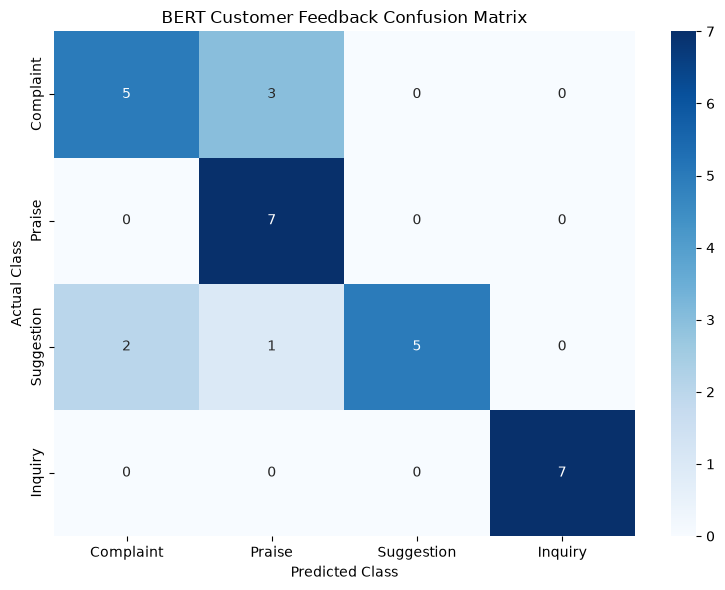


========== CUSTOMER FEEDBACK RESULT ==========
Input: The product arrived damaged and I want a replacement.
Predicted Class: Complaint
Confidence: 37.19%

========== CUSTOMER FEEDBACK RESULT ==========
Input: The product quality is excellent and I love it.
Predicted Class: Praise
Confidence: 39.15%

========== CUSTOMER FEEDBACK RESULT ==========
Input: Please add more payment methods to the website.
Predicted Class: Suggestion
Confidence: 47.67%

========== CUSTOMER FEEDBACK RESULT ==========
Input: When will my order be delivered?
Predicted Class: Inquiry
Confidence: 50.04%


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.87it/s]


Trained model saved successfully!
Model directory: ./saved_bert_feedback_model

Generated project files:
1. customer_feedback.csv
2. classification_report.csv
3. confusion_matrix.png
4. test_predictions.csv
5. saved_bert_feedback_model/


In [6]:
# ============================================================
# BERT CUSTOMER FEEDBACK CLASSIFIER
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ------------------------------------------------------------
# 2. CREATE CUSTOMER FEEDBACK DATASET
# ------------------------------------------------------------

feedback_data = {
    "Complaint": [
        "The product arrived damaged.",
        "I received a defective product.",
        "My order was delivered late.",
        "The item stopped working after one day.",
        "I want a refund for this product.",
        "The package was broken when delivered.",
        "The product quality is very poor.",
        "I am unhappy with the service.",
        "My payment was deducted twice.",
        "The wrong item was delivered.",
        "The product is missing from my order.",
        "The delivery person was rude.",
        "The item does not work properly.",
        "I received an empty package.",
        "I want a replacement for the damaged item.",
        "My order has not arrived on time.",
        "The product is completely different from the picture.",
        "I am disappointed with this purchase.",
        "The customer service did not solve my problem.",
        "The product arrived damaged and I want a replacement.",
        "The item was broken during shipping.",
        "I have been charged an incorrect amount.",
        "The app keeps crashing when I open it.",
        "I am frustrated with the poor delivery service.",
        "My refund has not been processed.",
        "The product I received is defective.",
        "The parcel arrived with missing parts.",
        "The product stopped working immediately.",
        "I want to report a problem with my order.",
        "This purchase was a terrible experience."
    ],

    "Praise": [
        "The product quality is excellent.",
        "I am very happy with my purchase.",
        "The delivery was quick and smooth.",
        "The customer service was wonderful.",
        "This product works perfectly.",
        "I love the quality of this item.",
        "The packaging was excellent.",
        "The product exceeded my expectations.",
        "The staff were very helpful.",
        "I would definitely recommend this product.",
        "The delivery arrived earlier than expected.",
        "The product is worth the money.",
        "The website is easy to use.",
        "I had a fantastic shopping experience.",
        "The support team solved my issue quickly.",
        "Everything arrived in perfect condition.",
        "I am impressed with the product quality.",
        "The service was excellent.",
        "This is one of my best purchases.",
        "The product is exactly what I wanted.",
        "The quality is outstanding.",
        "The ordering process was very smooth.",
        "I am satisfied with the fast delivery.",
        "The staff were polite and professional.",
        "This product is amazing.",
        "The product is reliable and easy to use.",
        "I received excellent customer support.",
        "The packaging was neat and secure.",
        "I am delighted with my purchase.",
        "The product works better than expected."
    ],

    "Suggestion": [
        "Please add more colour options.",
        "You should improve the packaging.",
        "Please make the delivery faster.",
        "It would be helpful to add a dark mode.",
        "Consider offering more payment methods.",
        "Please improve the mobile application.",
        "You should provide more product sizes.",
        "It would be great to have a wishlist feature.",
        "Please add better product descriptions.",
        "Consider extending customer support hours.",
        "Please make the website easier to navigate.",
        "You should offer more affordable plans.",
        "Please improve the search functionality.",
        "It would be useful to track orders in real time.",
        "Consider adding a product comparison feature.",
        "Please provide more detailed product images.",
        "You should simplify the checkout process.",
        "Please add an option for gift wrapping.",
        "It would be helpful to receive delivery notifications.",
        "Consider offering more discount options.",
        "Please improve the filter options.",
        "You should add multilingual support.",
        "Please make the application load faster.",
        "It would be nice to have a loyalty program.",
        "Consider improving the return process.",
        "Please add more product categories.",
        "You should provide clearer size charts.",
        "Please introduce a subscription option.",
        "It would be helpful to save multiple addresses.",
        "Please improve the overall user interface."
    ],

    "Inquiry": [
        "When will my order arrive?",
        "How can I track my package?",
        "What payment methods do you accept?",
        "Is this product available in blue?",
        "Can I cancel my order?",
        "How long does delivery take?",
        "What is your return policy?",
        "Is there a warranty for this product?",
        "How can I contact customer support?",
        "Do you offer international shipping?",
        "When will this item be back in stock?",
        "Can I change my delivery address?",
        "What are the available product sizes?",
        "How do I apply a discount code?",
        "Is cash on delivery available?",
        "Can I exchange this product?",
        "How much does shipping cost?",
        "Where can I find my invoice?",
        "Do you provide installation services?",
        "Can I order this item in bulk?",
        "What are your customer support hours?",
        "Is this product compatible with my device?",
        "How can I update my account details?",
        "When will my refund be credited?",
        "Do you have a physical store?",
        "Can I pay using a credit card?",
        "What is the estimated delivery date?",
        "How do I create an account?",
        "Is the product currently in stock?",
        "Can you explain the product warranty?"
    ]
}

# Convert dictionary into a DataFrame

rows = []

for category, feedback_list in feedback_data.items():
    for feedback in feedback_list:
        rows.append({
            "text": feedback,
            "label": category
        })

df = pd.DataFrame(rows)

# Convert category names to numeric labels

labels = ["Complaint", "Praise", "Suggestion", "Inquiry"]

label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["label"].map(label2id)

print("Dataset loaded successfully!")
print("Total feedback records:", len(df))
print("\nClass distribution:")
print(df["label"].map(id2label).value_counts())

# Save dataset

df.to_csv("customer_feedback.csv", index=False)

# ------------------------------------------------------------
# 3. SPLIT DATASET
# ------------------------------------------------------------

train_df, test_df = train_test_split(
    df,
    test_size=0.25,
    random_state=42,
    stratify=df["label"]
)

train_dataset = Dataset.from_pandas(
    train_df.reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df.reset_index(drop=True)
)

print("\nTraining records:", len(train_dataset))
print("Testing records:", len(test_dataset))

# ------------------------------------------------------------
# 4. LOAD BERT TOKENIZER
# ------------------------------------------------------------

MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("\nBERT tokenization completed!")

# ------------------------------------------------------------
# 5. LOAD PRETRAINED BERT CLASSIFIER
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

print("\nBERT model loaded successfully!")

# ------------------------------------------------------------
# 6. DEFINE EVALUATION METRICS
# ------------------------------------------------------------

def compute_metrics(eval_pred):

    logits, true_labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# ------------------------------------------------------------
# 7. CONFIGURE TRAINING
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir="./bert_feedback_results",
    num_train_epochs=4,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    seed=42
)

# ------------------------------------------------------------
# 8. CREATE TRAINER
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# ------------------------------------------------------------
# 9. TRAIN BERT
# ------------------------------------------------------------

print("\nStarting BERT fine-tuning...")

trainer.train()

print("\nTraining completed!")

# ------------------------------------------------------------
# 10. EVALUATE ON UNSEEN TEST DATA
# ------------------------------------------------------------

results = trainer.evaluate(tokenized_test)

print("\n========== EVALUATION METRICS ==========")

print(f"Accuracy  : {results['eval_accuracy']:.4f}")
print(f"Precision : {results['eval_precision']:.4f}")
print(f"Recall    : {results['eval_recall']:.4f}")
print(f"F1-score  : {results['eval_f1']:.4f}")

# ------------------------------------------------------------
# 11. GENERATE CLASSIFICATION REPORT
# ------------------------------------------------------------

pred_output = trainer.predict(tokenized_test)

y_true = pred_output.label_ids

y_pred = np.argmax(
    pred_output.predictions,
    axis=1
)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    digits=4,
    zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")
print(report)

# Save classification report

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    "classification_report.csv"
)

# ------------------------------------------------------------
# 12. GENERATE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(labels)))
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("BERT Customer Feedback Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 13. TEST NEW CUSTOMER FEEDBACK
# ------------------------------------------------------------

def predict_feedback(text):

    model.eval()

    device = next(model.parameters()).device

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=1
    )[0]

    predicted_id = torch.argmax(probabilities).item()

    predicted_class = id2label[predicted_id]

    confidence = probabilities[predicted_id].item() * 100

    print("\n========== CUSTOMER FEEDBACK RESULT ==========")
    print("Input:", text)
    print("Predicted Class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    return predicted_class, confidence


sample_feedback = (
    "The product arrived damaged and I want a replacement."
)

predict_feedback(sample_feedback)

# Test additional feedback

predict_feedback(
    "The product quality is excellent and I love it."
)

predict_feedback(
    "Please add more payment methods to the website."
)

predict_feedback(
    "When will my order be delivered?"
)

# ------------------------------------------------------------
# 14. SAVE TRAINED MODEL AND TOKENIZER
# ------------------------------------------------------------

MODEL_DIR = "./saved_bert_feedback_model"

trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("\nTrained model saved successfully!")
print("Model directory:", MODEL_DIR)

# ------------------------------------------------------------
# 15. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual": [id2label[i] for i in y_true],
    "Predicted": [id2label[i] for i in y_pred]
})

prediction_df.to_csv(
    "test_predictions.csv",
    index=False
)

print("\nGenerated project files:")
print("1. customer_feedback.csv")
print("2. classification_report.csv")
print("3. confusion_matrix.png")
print("4. test_predictions.csv")
print("5. saved_bert_feedback_model/")